In [96]:
from acconeer.exptool.a121._core.recording import open_record
from acconeer.exptool.a121.algo.presence._detector import _load_algo_data, Detector
from acconeer.exptool.a121.algo.presence._processors import Processor

from record_bikes import load_event_data

import matplotlib.pyplot as plt
# from scipy.signal import find_peaks
from find_peaks import find_peaks
import numpy as np

In [2]:
def get_intra_scores(record_path):
    with open_record(record_path) as record:
        algo_group = record.get_algo_group("presence_detector")
        sensor_id, detector_config, detector_context = _load_algo_data(algo_group)

        session = record.session(0)

        # FIX: Extract correct SensorConfig from SessionConfig
        sensor_config = session.session_config.sensor_config
        metadata = session.extended_metadata[0][sensor_id]

        processor_config = Detector._get_processor_config(detector_config)

        processor = Processor(
            sensor_config=sensor_config,
            metadata=metadata,
            processor_config=processor_config,
            context=detector_context
        )


        intra_scores = []

        for frame_data in session.extended_results:
            result_dict = frame_data[0]  # assuming one group
            result = result_dict[sensor_id]  # this is already an a121.Result

            processor_result = processor.process(result)
            intra_scores.append(processor_result.intra_presence_score)

    return intra_scores

In [3]:
FRAME_RATE = 10

test_paths = ['../tests/test2/test2.1', '../tests/test2/test2.2']
# test_paths = ['../tests/test2/test2.2']

In [4]:
# load tests data

all_intra_scores = []
timestamps = { 'BIKE':[], 'RUNNER':[], 'LARGE TRUCK':[] }

t_offset = 0
for i, test_path in enumerate(test_paths):

    # laod intra scores
    intra_scores = get_intra_scores(test_path + '.h5')

    print("Session ", i)
    print("-- # frames:", len(intra_scores))
    print("-- time:", len(intra_scores) / FRAME_RATE, "seconds")

    all_intra_scores.extend(intra_scores)

    # load timestampts
    events = load_event_data(test_path + '.csv')

    bike_t = [x + t_offset for x in events['BIKE']] if 'BIKE' in events else []
    runner_t = [x + t_offset for x in events['RUNNER']] if 'RUNNER' in events else []
    truck_t = [x + t_offset for x in events['LARGE TRUCK']] if 'LARGE TRUCK' in events else []
    t_offset = t_offset + len(intra_scores) / FRAME_RATE

    print("-- # BIKE:", len(bike_t))
    print("-- # RUNNER:", len(runner_t))
    print("-- # LARGE TRUCK:", len(truck_t))

    timestamps['BIKE'].extend(bike_t)
    timestamps['RUNNER'].extend(runner_t)
    timestamps['LARGE TRUCK'].extend(truck_t)

    print()
    
print("Total frames:", len(all_intra_scores))
print("Total time:", len(all_intra_scores) / FRAME_RATE, "seconds")
print("Total BIKE:", len(timestamps['BIKE']))
print("Total RUNNER:", len(timestamps['RUNNER']))
print("Total LARGE TRUCK:", len(timestamps['LARGE TRUCK']))

Session  0
-- # frames: 7807
-- time: 780.7 seconds
-- # BIKE: 45
-- # RUNNER: 0
-- # LARGE TRUCK: 0

Session  1
-- # frames: 8855
-- time: 885.5 seconds
-- # BIKE: 69
-- # RUNNER: 3
-- # LARGE TRUCK: 0

Total frames: 16662
Total time: 1666.2 seconds
Total BIKE: 114
Total RUNNER: 3
Total LARGE TRUCK: 0


# Original presence score

In [103]:
# find peaks
peaks = find_peaks(all_intra_scores, buffer_size=3, min_height=2, min_distance=5, n_pos_samples=1)
print("Number of timestamps:", len(timestamps['BIKE']) + len(timestamps['RUNNER']) + len(timestamps['LARGE TRUCK']))
print("Number of detected peaks:", len(peaks))

Number of timestamps: 117
Number of detected peaks: 117


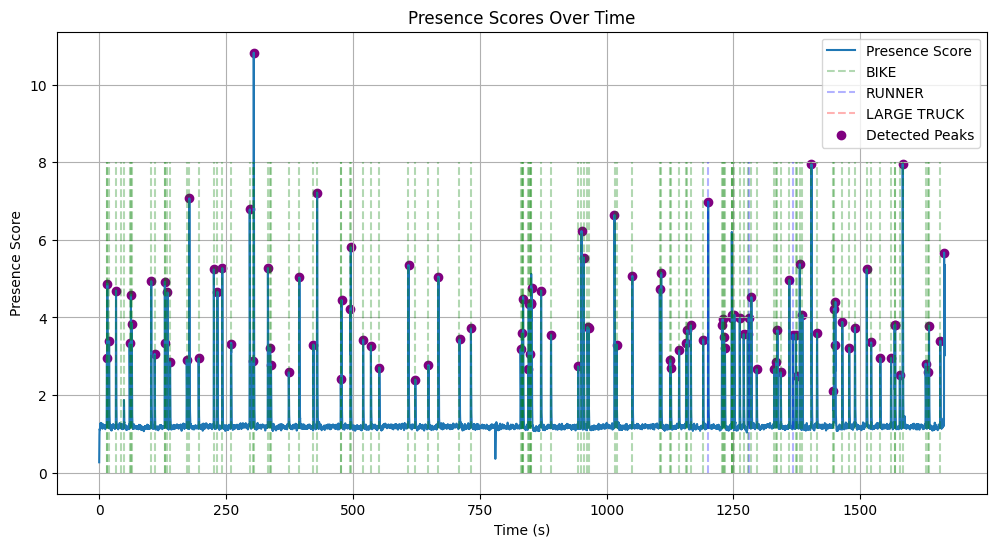

In [104]:
# plot
def plot_presence_scores(presence_scores, tsmps, pks=None, alpha=1):
    plt.figure(figsize=(12, 6))
    plt.plot(
        [i / FRAME_RATE for i in range(len(presence_scores))],
        presence_scores,
        alpha=alpha,
        label="Presence Score"
    )
    for label, times in tsmps.items():
        plt.vlines(
            times,
            ymin=0,
            ymax=8,
            alpha=0.3,
            colors=['g', 'b', 'r'][list(tsmps.keys()).index(label)],
            linestyles='dashed',
            label=label
        )
    if peaks.size > 0:
        plt.scatter(
            [peak / FRAME_RATE for peak in pks],
            [presence_scores[peak] for peak in pks],
            color='purple',
            alpha=1,
            marker='o',
            label='Detected Peaks'
        )
    plt.xlabel("Time (s)")
    plt.ylabel("Presence Score")
    plt.title("Presence Scores Over Time")
    plt.legend()
    plt.grid()

plot_presence_scores(all_intra_scores, timestamps, peaks)

(800.0, 1100.0)

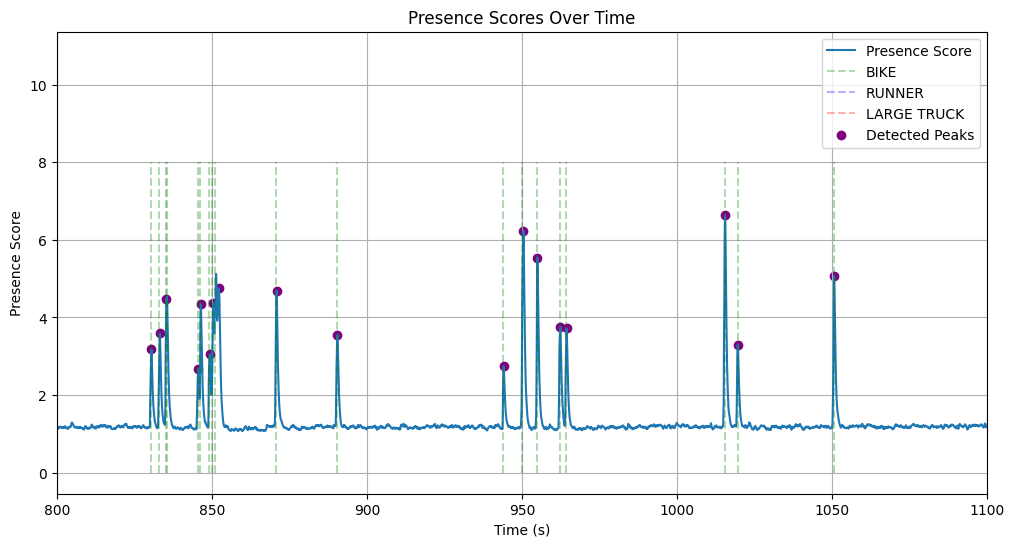

In [105]:
plot_presence_scores(all_intra_scores, timestamps, peaks)
width = 300
start = 800
plt.xlim(start, start+width)

### Matching peaks & timestamps

In [107]:
def report_unmatched(tmsps, pks, tolerance=1, verbose=True):
    remaining_pks = pks.copy()
    matched_tmsps = []
    matched_pks = []

    for t in tmsps:
        candidates = [(p, abs(t - p)) for p in remaining_pks if abs(t - p) <= tolerance]
        if candidates:
            closest_pk = min(candidates, key=lambda x: x[1])[0]
            matched_tmsps.append(t)
            matched_pks.append(closest_pk)
            remaining_pks.remove(closest_pk)

    unmatched_tmsps = [t for t in tmsps if t not in matched_tmsps]
    unmatched_pks = [p for p in pks if p not in matched_pks]

    if verbose:
        print("Unmatched tmsps:", len(unmatched_tmsps), 'timestamps', unmatched_tmsps)
        print("Unmatched peaks:", len(unmatched_pks), 'timestamps', unmatched_pks)

    return unmatched_tmsps, unmatched_pks



tmsps = []                                                      # tmsps are all timestamps, BIKE, RUNNER, LARGE TRUCK
for label, times in timestamps.items(): tmsps.extend(times)
pks = [p / FRAME_RATE for p in peaks]
_ = report_unmatched(tmsps, pks, verbose=True)

Unmatched tmsps: 4 timestamps [42.690219, 48.798128, 835.542149, 1247.678786]
Unmatched peaks: 4 timestamps [np.float64(852.2), np.float64(1450.0), np.float64(1450.8), np.float64(1665.1)]


(830.0, 855.0)

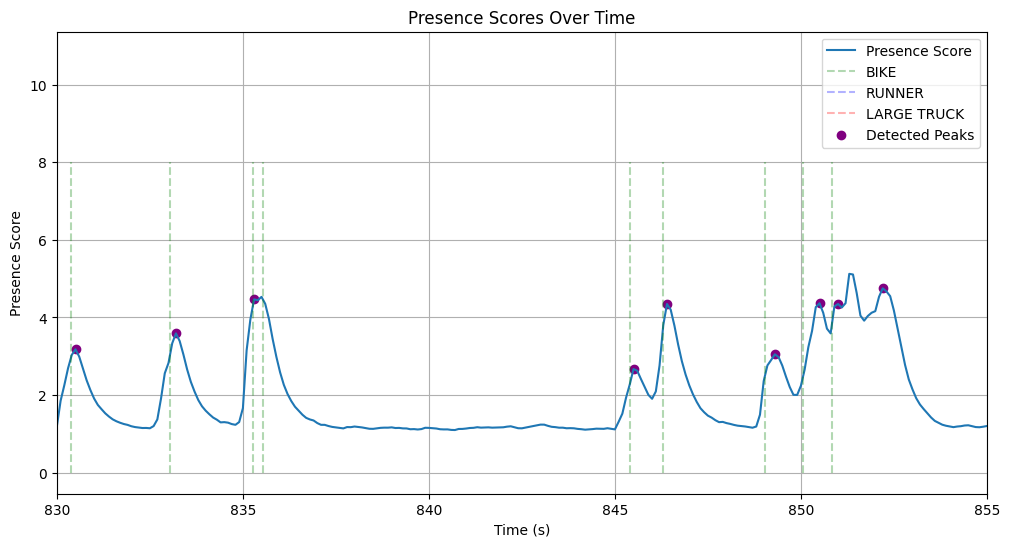

In [108]:
plot_presence_scores(all_intra_scores, timestamps, peaks)
width = 25
start = 830
plt.xlim(start, start+width)

(1240.0, 1250.0)

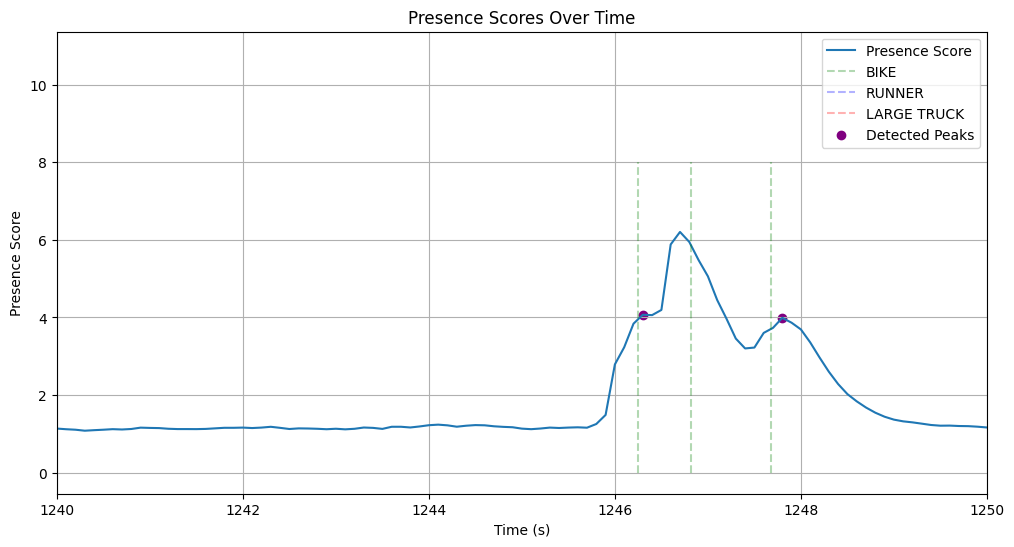

In [109]:
plot_presence_scores(all_intra_scores, timestamps, peaks)
width = 10
start = 1240
plt.xlim(start, start+width)

(1445.0, 1455.0)

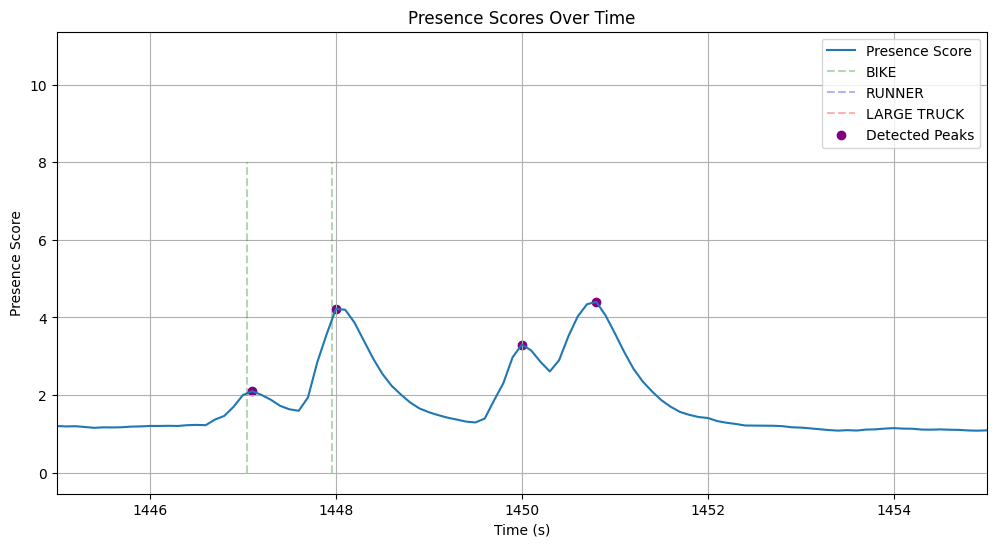

In [110]:
plot_presence_scores(all_intra_scores, timestamps, peaks)
width = 10
start = 1445
plt.xlim(start, start+width)

# mistery

# High Pass presence scores

Number of timestamps: 117
Number of detected peaks: 138


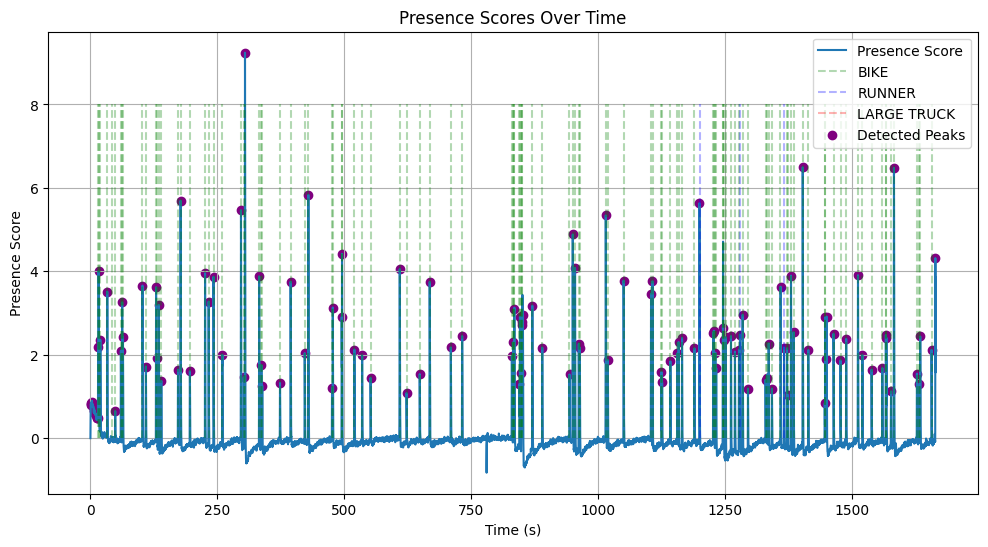

In [135]:
# first order HP filter
class HighPassFilter:
    def __init__(self, ALPHA):
        self.ALPHA = ALPHA
        self.prev_y = 0
        self.prev_x = None

    def update(self, x):
        if self.prev_x is None:
            self.prev_x = x
            return 0
        y = self.ALPHA * (self.prev_y + x - self.prev_x)
        self.prev_y = y
        self.prev_x = x
        return y


hpf = HighPassFilter(ALPHA=0.995)
high_passed = [hpf.update(x) for x in all_intra_scores]

# high_passed_peaks, _ = find_peaks(high_passed, height=0.2, distance=7)
high_passed_peaks = find_peaks(high_passed, buffer_size=3, min_height=0.2, min_distance=5, n_pos_samples=1)
print("Number of timestamps:", len(timestamps['BIKE']) + len(timestamps['RUNNER']) + len(timestamps['LARGE TRUCK']))
print("Number of detected peaks:", len(high_passed_peaks))

plot_presence_scores(high_passed, timestamps, high_passed_peaks)
# width = 300
# start = 800
# plt.xlim(start, start+width)

# High Pass presence scores Squeezed

Number of timestamps: 117
Number of detected peaks: 118


(800.0, 1100.0)

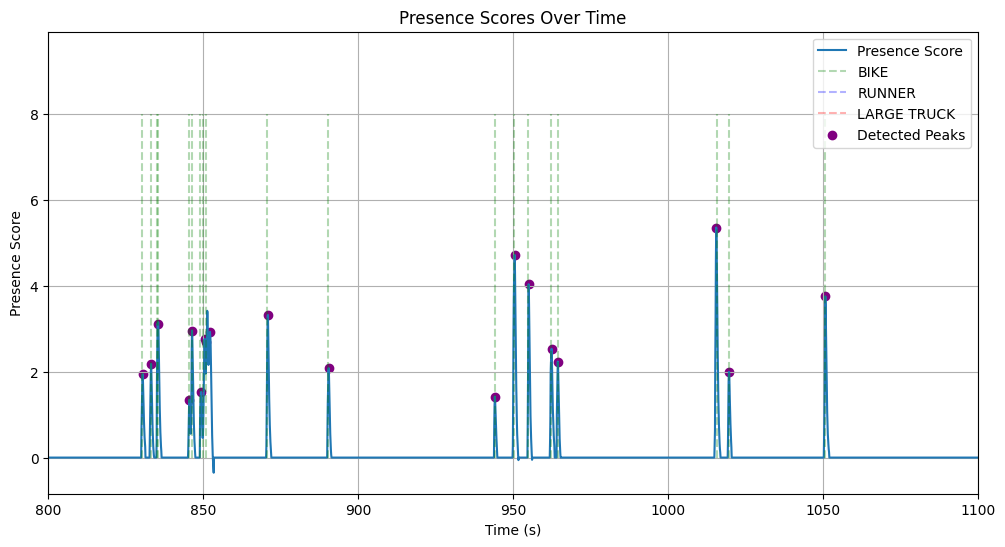

In [146]:
# first order HP filter
class HighPassFilter:
    def __init__(self, ALPHA, SQUEEZE):
        self.ALPHA = ALPHA
        self.SQUEEZE = SQUEEZE
        self.prev_y = 0
        self.prev_x = None

    def update(self, x):
        if self.prev_x is None:
            self.prev_x = x
            return 0
        y = self.ALPHA * (self.prev_y + x - self.prev_x) if x > self.SQUEEZE else 0
        self.prev_y = y
        self.prev_x = x
        return y


hpf = HighPassFilter(ALPHA=0.995, SQUEEZE=1.5)
high_passed_sq = [hpf.update(x) for x in all_intra_scores]

# high_passed_sq_peaks, _ = find_peaks(high_passed_sq, height=0.2, distance=7)
high_passed_sq_peaks = find_peaks(high_passed_sq, buffer_size=3, min_height=0.2, min_distance=5, n_pos_samples=1)
print("Number of timestamps:", len(timestamps['BIKE']) + len(timestamps['RUNNER']) + len(timestamps['LARGE TRUCK']))
print("Number of detected peaks:", len(high_passed_sq_peaks))

plot_presence_scores(high_passed_sq, timestamps, high_passed_sq_peaks)
width = 300
start = 800
plt.xlim(start, start+width)

### Matching peaks & timestamps

In [138]:
tmsps = []                                                      # tmsps are all timestamps, BIKE, RUNNER, LARGE TRUCK
for label, times in timestamps.items(): tmsps.extend(times)
pks = [peak / FRAME_RATE for peak in high_passed_sq_peaks]         # pks are all peaks in seconds
unmatched_tmsps, unmatched_pks = report_unmatched(tmsps, pks)

Unmatched tmsps: 3 timestamps [42.690219, 835.542149, 1247.678786]
Unmatched peaks: 4 timestamps [np.float64(852.2), np.float64(1450.0), np.float64(1450.8), np.float64(1665.1)]


(1245.0, 1255.0)

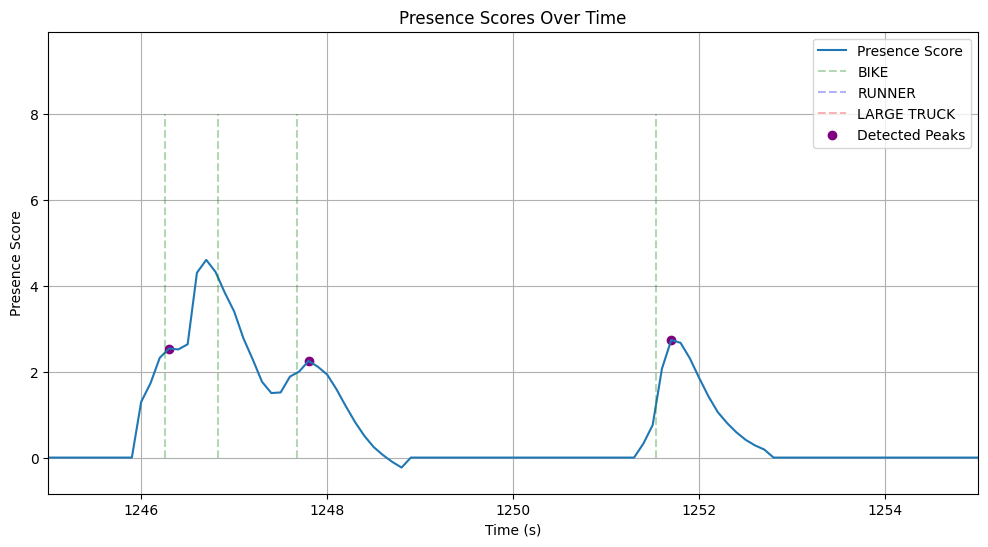

In [142]:
# plot unmatched timestamps
plot_presence_scores(high_passed_sq, timestamps, high_passed_peaks)
width = 10
start = 1245
plt.xlim(start, start+width)

(490.0, 500.0)

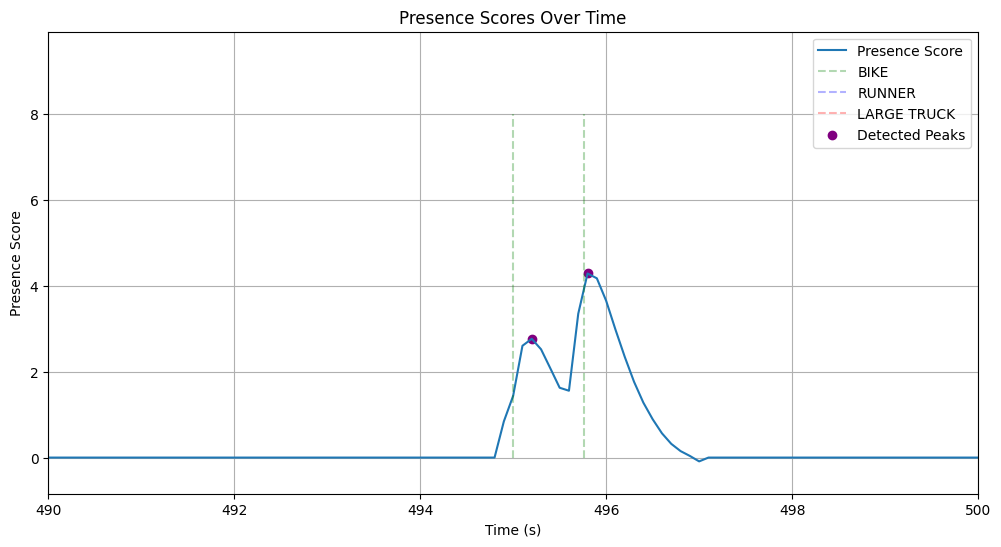

In [ ]:
# plot unmatched timestamps
plot_presence_scores(high_passed_sq, timestamps, high_passed_peaks)
width = 10
start = 490
plt.xlim(start, start+width)


# min_distance < 5 fixes it

(830.0, 860.0)

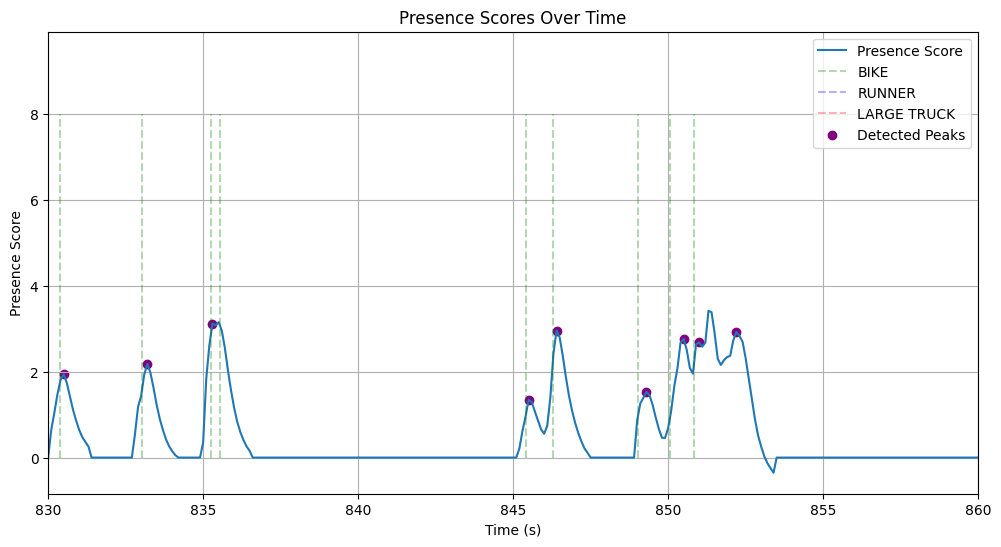

In [143]:
# plot unmatched timestamps
plot_presence_scores(high_passed_sq, timestamps, high_passed_peaks)
width = 30
start = 830
plt.xlim(start, start+width)


# too close

(40.0, 50.0)

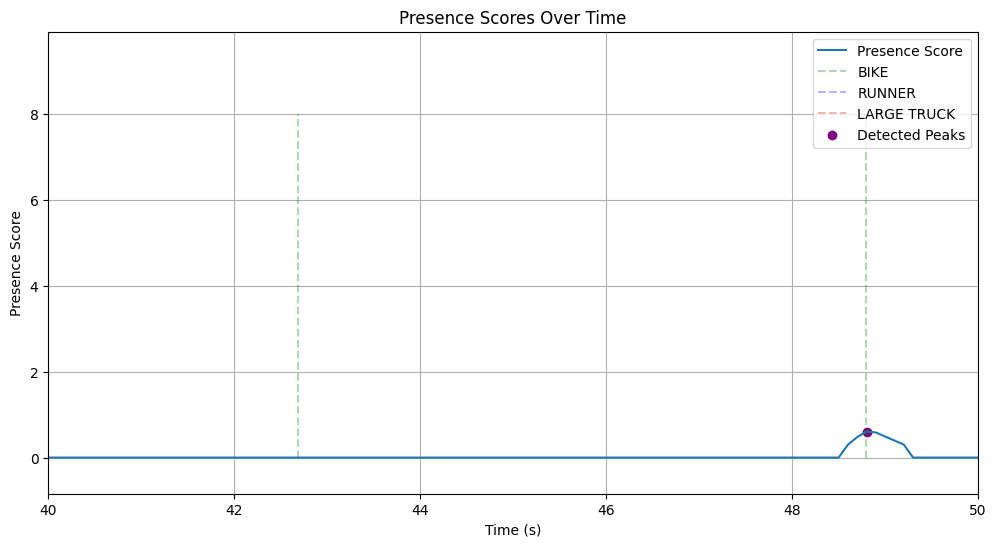

In [133]:
# plot unmatched timestamps
plot_presence_scores(high_passed_sq, timestamps, high_passed_sq_peaks)
width = 10
start = 40
plt.xlim(start, start+width)

# maybe accidental timestamp?

(1445.0, 1455.0)

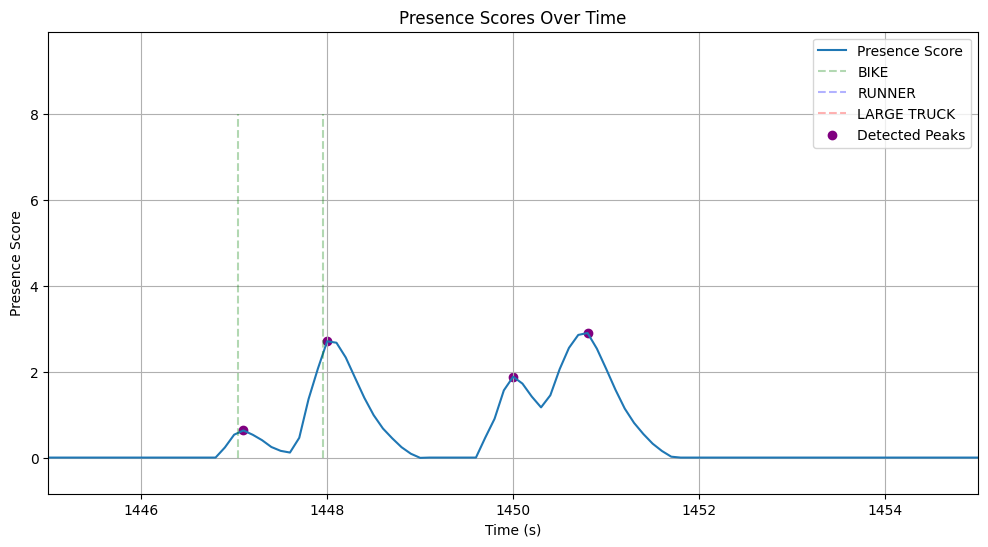

In [141]:
# plot unmatched pks
plot_presence_scores(high_passed_sq, timestamps, high_passed_sq_peaks)
width = 10
start = 1445
plt.xlim(start, start+width)

# mistery

Initial peak values: [np.float64(2.927393102157777), np.float64(1.4258131845461506), np.float64(2.4619787146547103), np.float64(4.369337079026405)]
Max initial peak value: 4.369337079026405


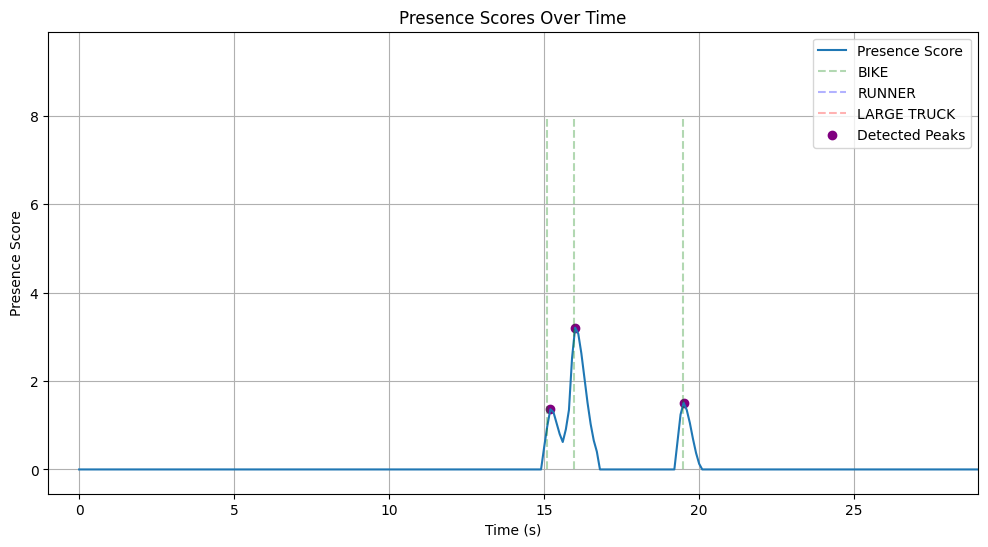

In [124]:
# plot unmatched timestamps
plot_presence_scores(high_passed_sq, timestamps, high_passed_sq_peaks)
width = 30
start = -1
plt.xlim(start, start+width)

# need to remove the starting error, maybe I can set a clock for this instead??
init_pk_vals = [high_passed_sq[int(pk * FRAME_RATE)] for pk in unmatched_pks[:5]]
print("Initial peak values:", init_pk_vals)
print("Max initial peak value:", max(init_pk_vals))